# Comparative Analysis of Ensemble Learning for Early Diabetes Detection

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import optuna
import warnings
import shap

from sklearn.impute import KNNImputer
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split

from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier
from sklearn.linear_model import LogisticRegression
from statistics import mean, stdev
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score

warnings.filterwarnings('ignore')
optuna.logging.set_verbosity(optuna.logging.WARNING)

## Exploratory Data Analysis (EDA)

In [2]:
df = pd.read_csv("diabetes.csv")
df.head()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               768 non-null    int64  
 1   Glucose                   768 non-null    int64  
 2   BloodPressure             768 non-null    int64  
 3   SkinThickness             768 non-null    int64  
 4   Insulin                   768 non-null    int64  
 5   BMI                       768 non-null    float64
 6   DiabetesPedigreeFunction  768 non-null    float64
 7   Age                       768 non-null    int64  
 8   Outcome                   768 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 54.1 KB


In [4]:
df.describe()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
count,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000
mean,3.845052,120.894531,69.105469,20.536458,79.799479,31.992578,0.471876,33.240885,0.348958
std,3.369578,31.972618,19.355807,15.952218,115.244002,7.884160,0.331329,11.760232,0.476951
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.078000,21.000000,0.000000
25%,1.000000,99.000000,62.000000,0.000000,0.000000,27.300000,0.243750,24.000000,0.000000
50%,3.000000,117.000000,72.000000,23.000000,30.500000,32.000000,0.372500,29.000000,0.000000
75%,6.000000,140.250000,80.000000,32.000000,127.250000,36.600000,0.626250,41.000000,1.000000
max,17.000000,199.000000,122.000000,99.000000,846.000000,67.100000,2.420000,81.000000,1.000000


In [5]:
missing_cols = ['Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI']
for col in missing_cols:
    zeros = (df[col] == 0).sum()
    print(f"{col}: {zeros} rows ({(zeros/len(df))*100:.2f}%)")

Glucose: 5 rows (0.65%)
BloodPressure: 35 rows (4.56%)
SkinThickness: 227 rows (29.56%)
Insulin: 374 rows (48.70%)
BMI: 11 rows (1.43%)


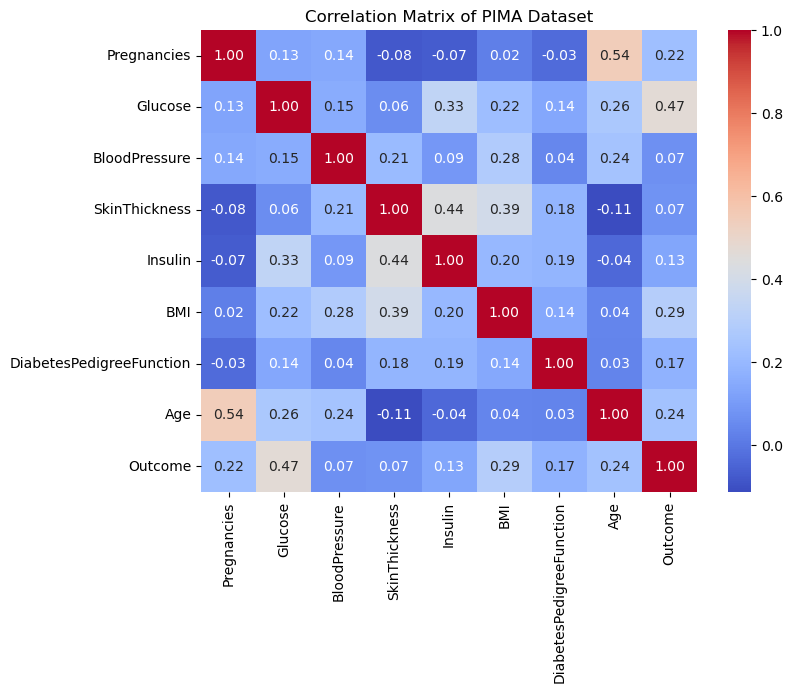

In [6]:
# Korelasi (Heatmap)
plt.figure(figsize=(8, 6))
sns.heatmap(df.corr(), annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Correlation Matrix of PIMA Dataset')
plt.show()

In [7]:
df['Outcome'].value_counts(normalize=True)

Outcome
0    0.651042
1    0.348958
Name: proportion, dtype: float64

## Data Preprocessing

In [8]:
X = df.drop('Outcome', axis=1)
y = df['Outcome']

In [9]:
# Handle Hidden Missing Values
columns_with_zeros = ['Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI']
X[columns_with_zeros] = X[columns_with_zeros].replace(0, np.nan)

print("Missing values per column:")
print(X.isnull().sum())

Missing values per column:
Pregnancies                   0
Glucose                       5
BloodPressure                35
SkinThickness               227
Insulin                     374
BMI                          11
DiabetesPedigreeFunction      0
Age                           0
dtype: int64


In [10]:
# KNN Imputation
imputer = KNNImputer(n_neighbors=5)
X_imputed = imputer.fit_transform(X)

In [11]:
# Feature Scaling
scaler = StandardScaler()
X_scaled_array = scaler.fit_transform(X_imputed)
X_scaled = pd.DataFrame(X_scaled_array, columns=X.columns)

## Data Splitting

In [12]:
X_dev, X_test, y_dev, y_test = train_test_split(
    X_scaled, y, 
    test_size=0.2, 
    stratify=y, 
    random_state=42
)

print(f"X_dev shape: {X_dev.shape}")
print(f"y_dev shape: {y_dev.shape}")
print(f"X_test shape: {X_test.shape}")
print(f"y_test shape: {y_test.shape}")

X_dev shape: (614, 8)
y_dev shape: (614,)
X_test shape: (154, 8)
y_test shape: (154,)


In [13]:
print("Class distribution in y_dev (normalized):")
print(y_dev.value_counts(normalize=True))
print()
print("Class distribution in y_test (normalized):")
print(y_test.value_counts(normalize=True))

Class distribution in y_dev (normalized):
Outcome
0    0.651466
1    0.348534
Name: proportion, dtype: float64

Class distribution in y_test (normalized):
Outcome
0    0.649351
1    0.350649
Name: proportion, dtype: float64


## Optimization & Individual Benchmarking

In [14]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

def objective_rf(trial):
    max_depth = trial.suggest_int('max_depth', 3, 12)
    n_estimators = trial.suggest_int('n_estimators', 100, 1000)
    
    model = RandomForestClassifier(
        max_depth=max_depth,
        n_estimators=n_estimators,
        random_state=42,
        n_jobs=-1
    )
    
    scores = cross_val_score(model, X_dev, y_dev, cv=cv, scoring='recall')
    return scores.mean()

def objective_et(trial):
    max_depth = trial.suggest_int('max_depth', 3, 12)
    n_estimators = trial.suggest_int('n_estimators', 100, 1000)
    
    model = ExtraTreesClassifier(
        max_depth=max_depth,
        n_estimators=n_estimators,
        random_state=42,
        n_jobs=-1
    )
    
    scores = cross_val_score(model, X_dev, y_dev, cv=cv, scoring='recall')
    return scores.mean()

def objective_xgb(trial):
    max_depth = trial.suggest_int('max_depth', 3, 12)
    learning_rate = trial.suggest_float('learning_rate', 0.01, 0.3)
    scale_pos_weight = trial.suggest_float('scale_pos_weight', 1.0, 3.0)
    
    model = XGBClassifier(
        max_depth=max_depth,
        learning_rate=learning_rate,
        scale_pos_weight=scale_pos_weight,
        random_state=42,
        verbosity=0
    )
    
    scores = cross_val_score(model, X_dev, y_dev, cv=cv, scoring='recall')
    return scores.mean()

def objective_lgbm(trial):
    max_depth = trial.suggest_int('max_depth', 3, 12)
    num_leaves = trial.suggest_int('num_leaves', 20, 150)
    learning_rate = trial.suggest_float('learning_rate', 0.01, 0.3)
    
    model = LGBMClassifier(
        max_depth=max_depth,
        num_leaves=num_leaves,
        learning_rate=learning_rate,
        random_state=42,
        verbosity=-1
    )
    
    scores = cross_val_score(model, X_dev, y_dev, cv=cv, scoring='recall')
    return scores.mean()

def objective_catboost(trial):
    depth = trial.suggest_int('depth', 4, 10)
    l2_leaf_reg = trial.suggest_int('l2_leaf_reg', 1, 10)
    learning_rate = trial.suggest_float('learning_rate', 0.01, 0.3)
    
    model = CatBoostClassifier(
        depth=depth,
        l2_leaf_reg=l2_leaf_reg,
        learning_rate=learning_rate,
        verbose=0,
        random_state=42
    )
    
    scores = cross_val_score(model, X_dev, y_dev, cv=cv, scoring='recall')
    return scores.mean()

In [15]:
# Optuna Hyperparameter Optimization (50 trials each model)

print("Optimizing Random Forest...")
study_rf = optuna.create_study(direction='maximize')
study_rf.optimize(objective_rf, n_trials=50, show_progress_bar=True)

print("Optimizing Extra Trees...")
study_et = optuna.create_study(direction='maximize')
study_et.optimize(objective_et, n_trials=50, show_progress_bar=True)

print("Optimizing XGBoost...")
study_xgb = optuna.create_study(direction='maximize')
study_xgb.optimize(objective_xgb, n_trials=50, show_progress_bar=True)

print("Optimizing LightGBM...")
study_lgbm = optuna.create_study(direction='maximize')
study_lgbm.optimize(objective_lgbm, n_trials=50, show_progress_bar=True)

print("Optimizing CatBoost...")
study_catboost = optuna.create_study(direction='maximize')
study_catboost.optimize(objective_catboost, n_trials=50, show_progress_bar=True)

Optimizing Random Forest...


  0%|          | 0/50 [00:00<?, ?it/s]

Optimizing Extra Trees...


  0%|          | 0/50 [00:00<?, ?it/s]

Optimizing XGBoost...


  0%|          | 0/50 [00:00<?, ?it/s]

Optimizing LightGBM...


  0%|          | 0/50 [00:00<?, ?it/s]

Optimizing CatBoost...


  0%|          | 0/50 [00:00<?, ?it/s]

In [16]:
results = {
    'Random Forest': study_rf.best_value,
    'Extra Trees': study_et.best_value,
    'XGBoost': study_xgb.best_value,
    'LightGBM': study_lgbm.best_value,
    'CatBoost': study_catboost.best_value
}

for model_name, best_recall in sorted(results.items(), key=lambda x: x[1], reverse=True):
    print(f"{model_name:20s} | Best Mean CV Recall: {best_recall:.4f}")

XGBoost              | Best Mean CV Recall: 0.8271
CatBoost             | Best Mean CV Recall: 0.6261
Random Forest        | Best Mean CV Recall: 0.6169
LightGBM             | Best Mean CV Recall: 0.5982
Extra Trees          | Best Mean CV Recall: 0.5703


In [17]:
# Store Best Parameters
best_params = {
    'Random Forest': study_rf.best_params,
    'Extra Trees': study_et.best_params,
    'XGBoost': study_xgb.best_params,
    'LightGBM': study_lgbm.best_params,
    'CatBoost': study_catboost.best_params
}

print("Best Parameters for each model:")
for model_name, params in best_params.items():
    print(f"\n{model_name}:")
    for param_name, param_value in params.items():
        print(f"  {param_name}: {param_value}")

Best Parameters for each model:

Random Forest:
  max_depth: 11
  n_estimators: 127

Extra Trees:
  max_depth: 11
  n_estimators: 150

XGBoost:
  max_depth: 4
  learning_rate: 0.026633029183091773
  scale_pos_weight: 2.733009158916918

LightGBM:
  max_depth: 3
  num_leaves: 63
  learning_rate: 0.07435666109162446

CatBoost:
  depth: 7
  l2_leaf_reg: 10
  learning_rate: 0.21770627579692642


## Stacking Integration

In [18]:
base_models = {
    'rf': RandomForestClassifier(max_depth=7, n_estimators=192, random_state=42, n_jobs=-1),
    'et': ExtraTreesClassifier(max_depth=12, n_estimators=129, random_state=42, n_jobs=-1),
    'xgb': XGBClassifier(max_depth=4, learning_rate=0.010945439800764805, scale_pos_weight=2.9933799996399655, random_state=42, verbosity=0),
    'lgbm': LGBMClassifier(max_depth=3, num_leaves=70, learning_rate=0.06886491921407106, random_state=42, verbosity=-1),
    'catboost': CatBoostClassifier(depth=7, l2_leaf_reg=6, learning_rate=0.04615427041339043, random_state=42, verbose=0)
}

# Out-of-Fold Meta-Features for Training
oof_train = np.zeros((len(X_dev), len(base_models)))
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

for fold, (train_idx, val_idx) in enumerate(cv.split(X_dev, y_dev)):
    X_train_fold = X_dev.iloc[train_idx]
    X_val_fold = X_dev.iloc[val_idx]
    y_train_fold = y_dev.iloc[train_idx]
    
    for col_idx, (model_name, model) in enumerate(base_models.items()):
        model.fit(X_train_fold, y_train_fold)
        oof_train[val_idx, col_idx] = model.predict_proba(X_val_fold)[:, 1]

# Meta-Features for the Final Test Set
oof_test = np.zeros((len(X_test), len(base_models)))

for col_idx, (model_name, model) in enumerate(base_models.items()):
    model.fit(X_dev, y_dev)
    oof_test[:, col_idx] = model.predict_proba(X_test)[:, 1]

In [19]:
X_dev_meta = pd.DataFrame(oof_train, columns=['rf', 'et', 'xgb', 'lgbm', 'catboost'])
X_test_meta = pd.DataFrame(oof_test, columns=['rf', 'et', 'xgb', 'lgbm', 'catboost'])

# Train the Meta-Learner
meta_learner = LogisticRegression(class_weight='balanced', random_state=42)
meta_learner.fit(X_dev_meta, y_dev)

print(f"X_dev_meta shape: {X_dev_meta.shape}")

X_dev_meta shape: (614, 5)


## Final Evaluation & Interpretability (SHAP)


In [20]:
y_pred = meta_learner.predict(X_test_meta)
y_prob = meta_learner.predict_proba(X_test_meta)[:, 1]

# Threshold Tuning
tuned_threshold = 0.38
y_pred_tuned = (y_prob >= tuned_threshold).astype(int)

accuracy = accuracy_score(y_test, y_pred_tuned)
precision = precision_score(y_test, y_pred_tuned)
recall = recall_score(y_test, y_pred_tuned)
f1 = f1_score(y_test, y_pred_tuned)
roc_auc = roc_auc_score(y_test, y_prob)


print(f"Accuracy: {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall: {recall:.4f}")
print(f"F1-Score: {f1:.4f}")
print(f"ROC-AUC: {roc_auc:.4f}")

Accuracy: 0.7208
Precision: 0.5679
Recall: 0.8519
F1-Score: 0.6815
ROC-AUC: 0.8156


In [21]:
def predict_stacking_proba(X_input):
    if isinstance(X_input, np.ndarray):
        X_input = pd.DataFrame(X_input, columns=X_dev.columns)
    
    temp_meta_features = np.zeros((len(X_input), len(base_models)))
    for col_idx, (model_name, model) in enumerate(base_models.items()):
        temp_meta_features[:, col_idx] = model.predict_proba(X_input)[:, 1]
    
    return meta_learner.predict_proba(temp_meta_features)[:, 1]

background_data = shap.sample(X_dev, 20)
explainer = shap.KernelExplainer(predict_stacking_proba, background_data)
shap_values = explainer.shap_values(X_test)

  0%|          | 0/154 [00:00<?, ?it/s]

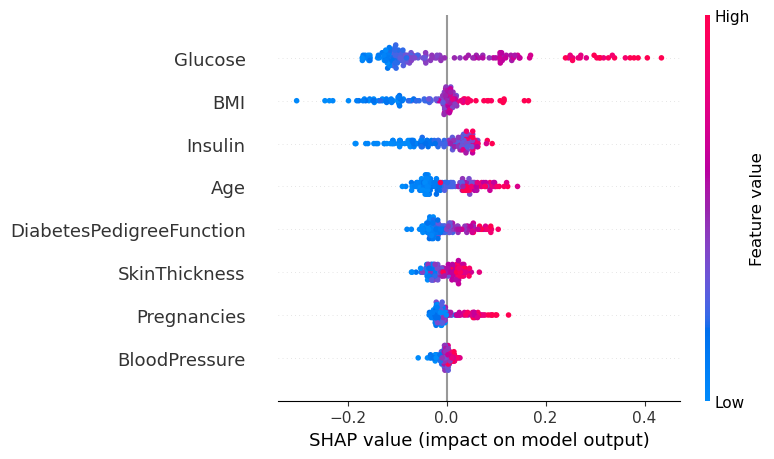

In [22]:
# Global Interpretability (SHAP Summary Plot)
shap.summary_plot(shap_values, X_test)


In [23]:
print(y_prob)
print(y_test.values)

[0.81706247 0.20246863 0.28927182 0.465202   0.11097168 0.37289723
 0.59506656 0.86161613 0.13407562 0.92183617 0.7034494  0.71998222
 0.18739274 0.21475285 0.3220241  0.57628347 0.86497798 0.1420729
 0.87936139 0.1918103  0.29292593 0.87221909 0.42629018 0.89619291
 0.65189489 0.13791211 0.82184995 0.10853959 0.51252744 0.12228075
 0.11775299 0.13975518 0.57715664 0.71344354 0.865102   0.27264299
 0.28493076 0.14605204 0.82927733 0.64328834 0.64058299 0.19060956
 0.16096249 0.51128568 0.28780916 0.52846796 0.18169682 0.17844268
 0.86272499 0.43315015 0.76695255 0.7926362  0.58405332 0.11902618
 0.71345913 0.52317622 0.79321394 0.22631345 0.91275258 0.23211898
 0.88306237 0.41770768 0.11541478 0.93363761 0.11377453 0.60674188
 0.90516567 0.1098839  0.46773512 0.83195146 0.19689826 0.14516488
 0.51214893 0.63936347 0.12713548 0.41197068 0.13967162 0.57732993
 0.14941114 0.12456342 0.1193977  0.47345111 0.11629703 0.43265879
 0.35677961 0.1553867  0.56663816 0.51861965 0.14723325 0.49337

<Figure size 1400x400 with 0 Axes>

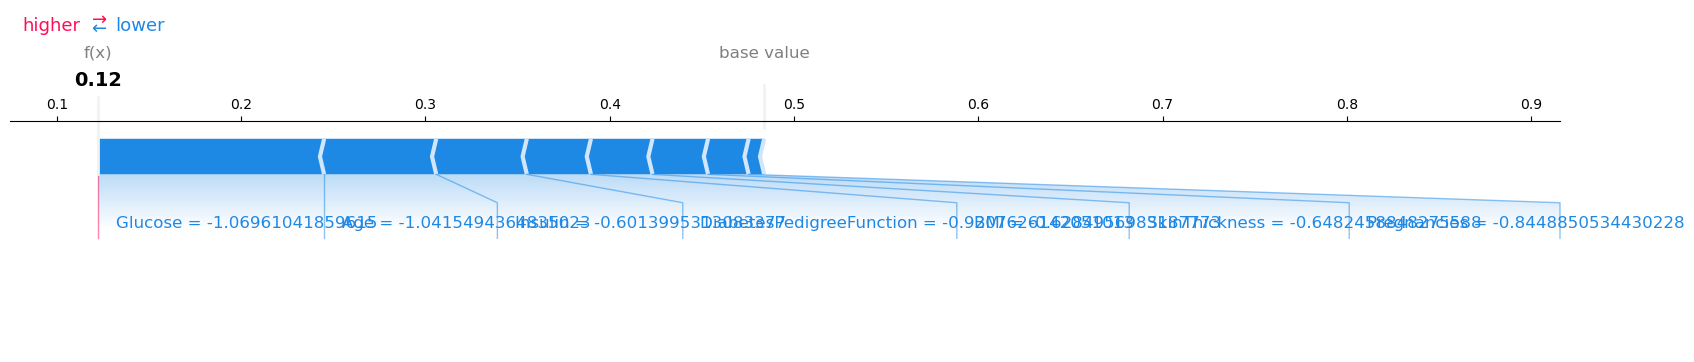

<Figure size 640x480 with 0 Axes>

In [24]:
# Local Interpretability (SHAP Force Plot for Individual Patient)
plt.figure(figsize=(14, 4))
shap.initjs()
shap.force_plot(
    explainer.expected_value, 
    shap_values[29], 
    X_test.iloc[29], 
    matplotlib=True
)
plt.tight_layout()
plt.show()

In [25]:
idx = X_test.index[29]
print(df.loc[idx])

Pregnancies                  1.000
Glucose                     89.000
BloodPressure               66.000
SkinThickness               23.000
Insulin                     94.000
BMI                         28.100
DiabetesPedigreeFunction     0.167
Age                         21.000
Outcome                      0.000
Name: 3, dtype: float64


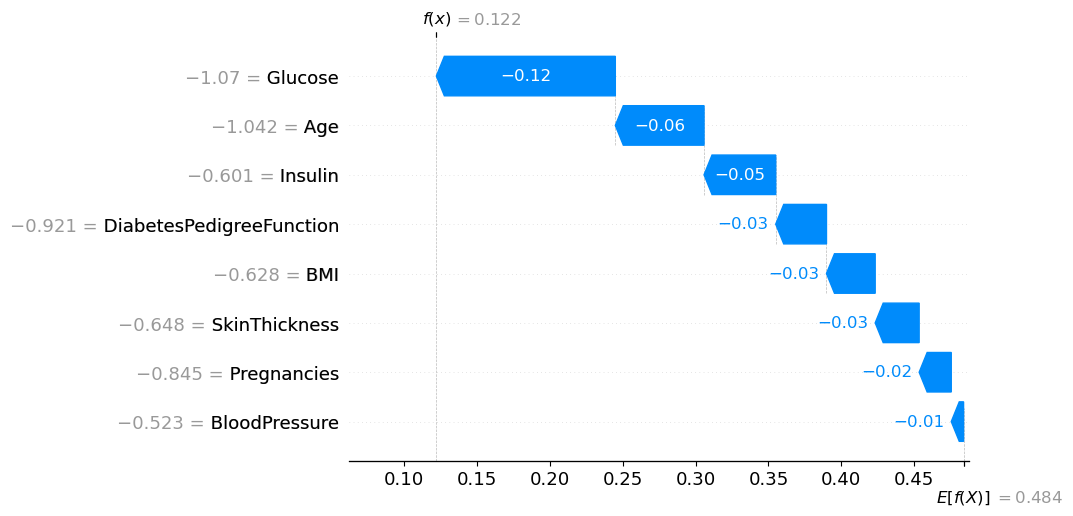

<Figure size 640x480 with 0 Axes>

In [26]:
# Waterfall Plot (for Individual Patients)
shap.plots.waterfall(shap.Explanation(
    values=shap_values[29], 
    base_values=explainer.expected_value, 
    data=X_test.iloc[29]
))
plt.tight_layout()
plt.show()